In [1]:
# Import core numerical and data manipulation libraries
import pandas as pd
import numpy as np   

# Import data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns 

# Import feature scaling tools from scikit-learn
from sklearn.preprocessing import MinMaxScaler, StandardScaler


In [2]:
# Load the Pima Indians Diabetes dataset from CSV
df = pd.read_csv('diabetes.csv.xls')

# Preview the first 5 records of the dataset
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Display structural metadata: column names, data types, and non-null counts
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
# Generate descriptive summary statistics (mean, std, min, quartiles, max)
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
# Inspect the dimensions of the dataset (number of rows, number of columns)
df.shape


(768, 9)

In [6]:
# Check for missing (null) values across all columns
df.isnull().sum()


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

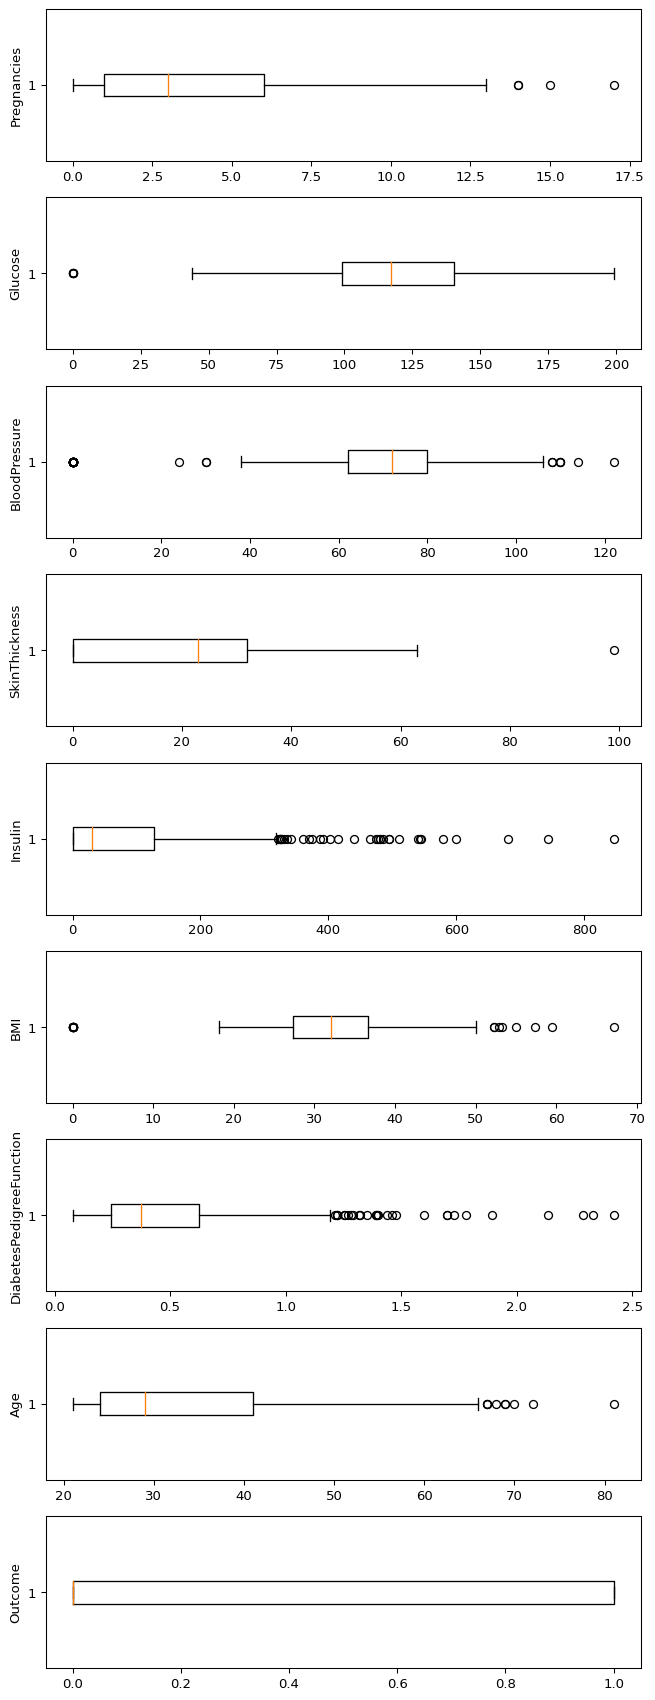

In [7]:
# Create vertical subplots to inspect feature distributions and detect outliers via boxplots
fig, axs = plt.subplots(len(df.columns), 1, figsize=(7, 18), dpi=95)

# Generate a horizontal boxplot for each feature column
for i, col in enumerate(df.columns):
    axs[i].boxplot(df[col], vert=False)  
    axs[i].set_ylabel(col, fontsize=10)

# Adjust layout spacing and display the figure
plt.tight_layout()
plt.show()


In [8]:
# Detect and filter outliers in the 'Insulin' feature using the Interquartile Range (IQR) method
# Calculate 25th (Q1) and 75th (Q3) percentiles
q1, q3 = np.percentile(df['Insulin'], [25, 75])

# Compute IQR and define lower and upper cutoff thresholds (1.5 * IQR rule)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr    

# Filter dataframe to retain only records within the non-outlier boundary
clean_df = df[(df['Insulin'] >= lower) & (df['Insulin'] <= upper)]


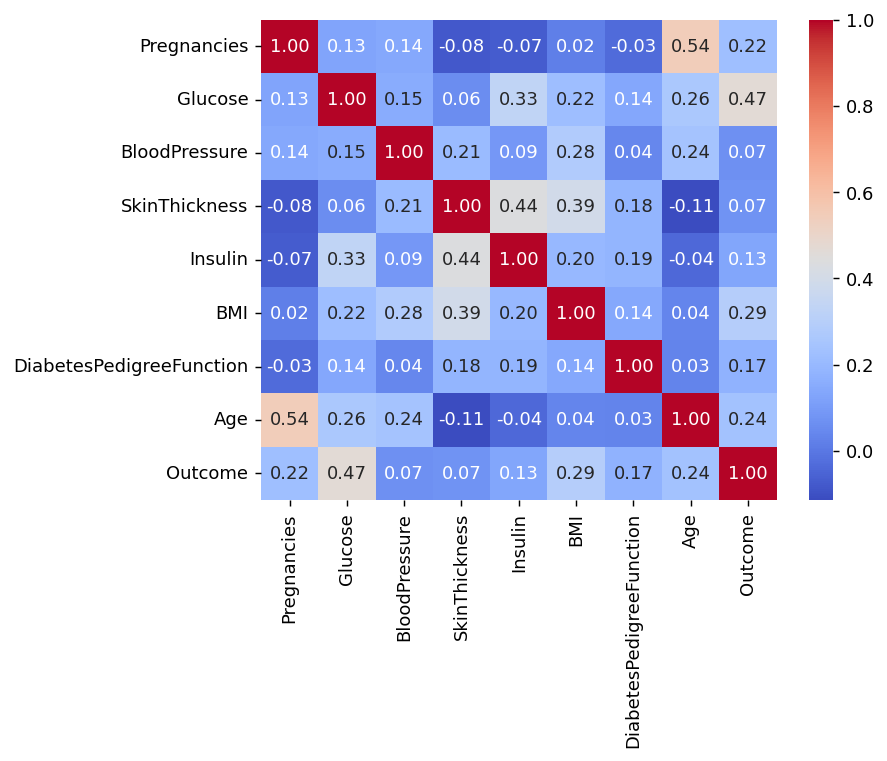

Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64


In [9]:
# Calculate pairwise Pearson correlation coefficients between numerical features
corr = df.corr()

# Visualize the correlation matrix as an annotated heatmap
plt.figure(dpi=130)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

# Display correlations of all features with the target 'Outcome', sorted in descending order
print(corr['Outcome'].sort_values(ascending=False))


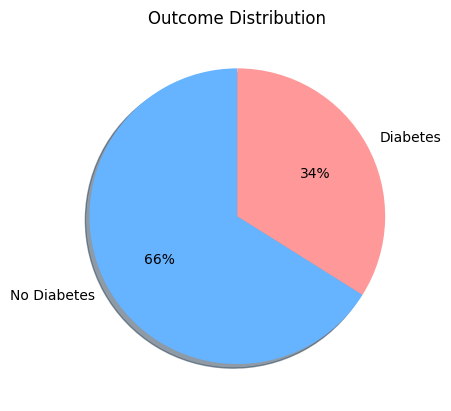

In [10]:
# Visualize target class balance (Outcome: 0 = No Diabetes, 1 = Diabetes) using a pie chart
plt.pie(
    clean_df['Outcome'].value_counts(),
    labels=['No Diabetes', 'Diabetes'],  # 0 is the majority class, 1 is the minority class
    autopct='%.f%%',                    # Display formatted percentage on each slice
    startangle=90,                      # Start first slice at 90 degrees
    colors=['#66b3ff', '#ff9999'],       # Distinct colors for clarity
    shadow=True                         # Enable shadow effect for visual contrast
)
plt.title('Outcome Distribution')
plt.show()


In [11]:
# Separate feature matrix (X) and target variable vector (y)
X = df.drop(columns=['Outcome'])
y = df['Outcome']


In [12]:
# Feature Scaling Technique 1: Min-Max Normalization (rescales values into range [0, 1])
scaler = MinMaxScaler() 
X_normalized = scaler.fit_transform(X)  

# Preview the first 5 rows of normalized feature values
print('X_normalized:\n', X_normalized[:5])


X_normalized:
 [[0.35294118 0.74371859 0.59016393 0.35353535 0.         0.50074516
  0.23441503 0.48333333]
 [0.05882353 0.42713568 0.54098361 0.29292929 0.         0.39642325
  0.11656704 0.16666667]
 [0.47058824 0.91959799 0.52459016 0.         0.         0.34724292
  0.25362938 0.18333333]
 [0.05882353 0.44723618 0.54098361 0.23232323 0.11111111 0.41877794
  0.03800171 0.        ]
 [0.         0.68844221 0.32786885 0.35353535 0.19858156 0.64232489
  0.94363792 0.2       ]]


In [13]:
# Feature Scaling Technique 2: Standardization / Z-score Scaling (centers data to mean=0, std=1)
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X)

# Preview the first 5 rows of standardized feature values
print('X_standardized:\n', X_standardized[:5])


X_standardized:
 [[ 0.63994726  0.84832379  0.14964075  0.90726993 -0.69289057  0.20401277
   0.46849198  1.4259954 ]
 [-0.84488505 -1.12339636 -0.16054575  0.53090156 -0.69289057 -0.68442195
  -0.36506078 -0.19067191]
 [ 1.23388019  1.94372388 -0.26394125 -1.28821221 -0.69289057 -1.10325546
   0.60439732 -0.10558415]
 [-0.84488505 -0.99820778 -0.16054575  0.15453319  0.12330164 -0.49404308
  -0.92076261 -1.04154944]
 [-1.14185152  0.5040552  -1.50468724  0.90726993  0.76583594  1.4097456
   5.4849091  -0.0204964 ]]
